# Kamień 1 – analiza danych HAM10000 i plan eksperymentów

Cel: klasyfikacja 7 typów zmian skórnych (CNN), nacisk na czerniaka + Grad-CAM.

Dane: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

DATA = Path("data")
SEED = 42
CLASSES = ["nv", "mel", "bkl", "bcc", "akiec", "vasc", "df"]

meta = pd.read_csv(DATA / "HAM10000_metadata.csv")
print(meta.shape, "| unikalne zmiany:", meta.lesion_id.nunique())
meta.head()

(10015, 8) | unikalne zmiany: 7470


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


## Rozkład klas

In [2]:
stats = pd.DataFrame({
    "zdjecia": meta.dx.value_counts(),
    "zmiany": meta.groupby("dx").lesion_id.nunique(),
}).loc[CLASSES]
stats["%"] = (100 * stats.zdjecia / len(meta)).round(1)
stats["zdj/zmiane"] = (stats.zdjecia / stats.zmiany).round(2)
stats

,zdjecia,zmiany,%,zdj/zmiane
dx,,,,
nv,6705,5403,66.9,1.24
mel,1113,614,11.1,1.81
bkl,1099,727,11.0,1.51
bcc,514,327,5.1,1.57
akiec,327,228,3.3,1.43
vasc,142,98,1.4,1.45
df,115,73,1.1,1.58


| Klasa | Opis |
|---|---|
| `nv` | znamię barwnikowe (melanocytic nevus) |
| `mel` | **czerniak** (melanoma) |
| `bkl` | łagodne zmiany typu rogowacenia (benign keratosis-like) |
| `bcc` | rak podstawnokomórkowy (basal cell carcinoma) |
| `akiec` | rogowacenie słoneczne / rak in situ (actinic keratosis / Bowen's disease) |
| `vasc` | zmiany naczyniowe (vascular lesions) |
| `df` | włókniak skóry (dermatofibroma) |

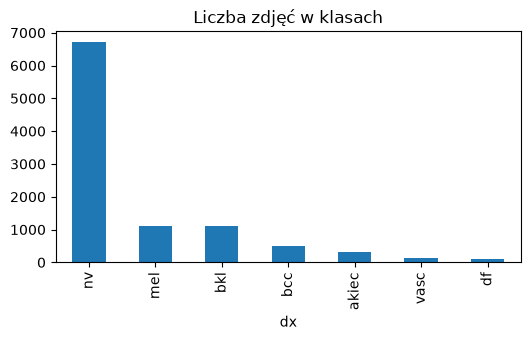

In [3]:
stats.zdjecia.plot.bar(figsize=(6, 3), title="Liczba zdjęć w klasach")
plt.show()

Duże niezbalansowanie (nv ok. 67%, df tylko 115 zdjęć). Model zawsze odpowiadający „nv” miałby ok. 67% accuracy,
dlatego główna metryka to balanced accuracy.

## Kilka zdjęć tej samej zmiany

In [4]:
per_lesion = meta.groupby("lesion_id").size()
print(per_lesion.value_counts().sort_index())
print("zdjęcia ze zmian z >1 zdjęciem:", (meta.lesion_id.map(per_lesion) > 1).sum())

1    5514
2    1423
3     490
4      34
5       5
6       4
Name: count, dtype: int64
zdjęcia ze zmian z >1 zdjęciem: 4501


Ok. 45% zdjęć to zmiany sfotografowane kilka razy (mel: 1113 zdjęć, tylko 614 zmian).
Podział musi być po `lesion_id`, inaczej te same zmiany trafią do train i test.

## Źródło zdjęć i potwierdzenie diagnozy

In [5]:
(100 * pd.crosstab(meta.dx, meta.dataset, normalize="index")).round(0).loc[CLASSES]

dataset,rosendahl,vidir_modern,vidir_molemax,vienna_dias
dx,,,,
nv,12.0,27.0,55.0,5.0
mel,31.0,61.0,2.0,6.0
bkl,45.0,43.0,11.0,1.0
bcc,58.0,41.0,0.0,1.0
akiec,90.0,10.0,0.0,0.0
vasc,2.0,58.0,38.0,2.0
df,26.0,44.0,26.0,3.0


In [6]:
pd.crosstab(meta.dx, meta.dx_type).loc[CLASSES]

dx_type,confocal,consensus,follow_up,histo
dx,,,,
nv,0,503,3704,2498
mel,0,0,0,1113
bkl,69,264,0,766
bcc,0,0,0,514
akiec,0,0,0,327
vasc,0,75,0,67
df,0,60,0,55


- akiec w 90% z jednego źródła (rosendahl), nv w 55% z vidir_molemax – model może uczyć się cech aparatu, do sprawdzenia Grad-CAM-em.
- wszystkie mel potwierdzone histopatologicznie.

## Przykładowe zdjęcia (wymaga pobranych obrazów)

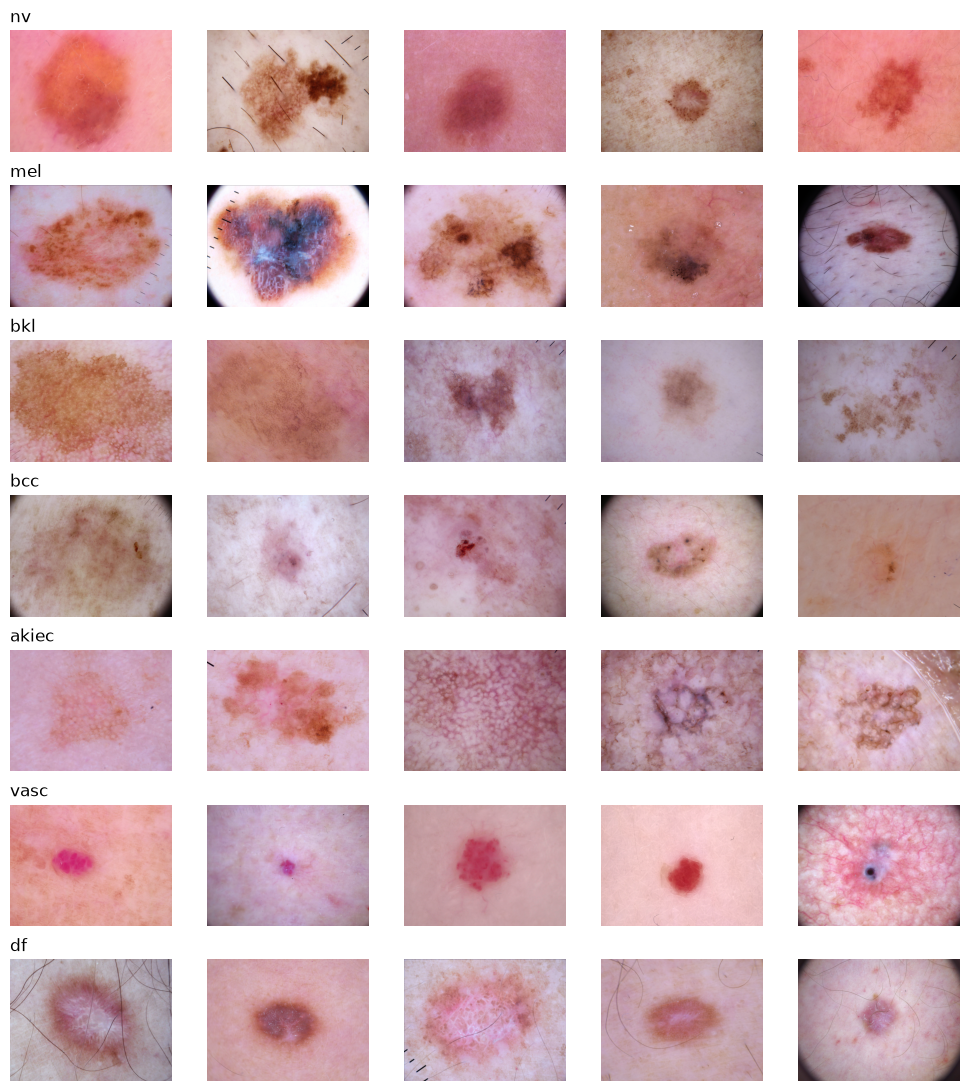

In [7]:
from PIL import Image

paths = {p.stem: p for p in DATA.rglob("ISIC_*.jpg")}
if paths:
    fig, axes = plt.subplots(len(CLASSES), 5, figsize=(10, 11))
    for i, c in enumerate(CLASSES):
        ids = meta[meta.dx == c].image_id.sample(5, random_state=SEED)
        for ax, img_id in zip(axes[i], ids):
            ax.imshow(Image.open(paths[img_id]))
            ax.axis("off")
        axes[i, 0].set_title(c, loc="left")
    plt.tight_layout()
    plt.show()
else:
    print("brak zdjęć w data/")

## Podział train / val / test (70/15/15) po lesion_id

In [8]:
# 20 foldów grupowanych po lesion_id: 3 -> test, 3 -> val, reszta -> train
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
fold = np.zeros(len(meta), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(meta, meta.dx, groups=meta.lesion_id)):
    fold[idx] = k
meta["split"] = np.select([fold < 3, fold < 6], ["test", "val"], "train")

assert (meta.groupby("lesion_id").split.nunique() == 1).all()  # żadna zmiana w dwóch zbiorach
meta[["image_id", "lesion_id", "dx", "split"]].to_csv(DATA / "splits.csv", index=False)

pd.crosstab(meta.dx, meta.split, margins=True).loc[CLASSES + ["All"], ["train", "val", "test", "All"]]

split,train,val,test,All
dx,,,,
nv,4694,1006,1005,6705
mel,779,166,168,1113
bkl,769,165,165,1099
bcc,359,77,78,514
akiec,228,50,49,327
vasc,100,21,21,142
df,80,18,17,115
All,7009,1503,1503,10015


Dla porównania – zwykły losowy podział po zdjęciach:

In [9]:
tr, te = train_test_split(meta, test_size=0.15, stratify=meta.dx, random_state=SEED)
leak = te.lesion_id.isin(tr.lesion_id)
print(f"zdjęcia testowe ze zmian obecnych w train: {leak.mean():.0%}")
(100 * leak.groupby(te.dx).mean()).round(0).loc[CLASSES]

zdjęcia testowe ze zmian obecnych w train: 40%


dx
nv       30.0
mel      69.0
bkl      55.0
bcc      65.0
akiec    53.0
vasc     50.0
df       82.0
Name: lesion_id, dtype: float64

Przy losowym podziale 40% testu (mel: 69%) to zmiany widziane w treningu – wyniki byłyby zawyżone.

## Plan eksperymentów

Metryki: balanced accuracy (główna), macro-F1, recall mel, AUC. Każdy wariant 3 seedy (średnia ± std).
Zmieniam jeden czynnik naraz względem E3. Wybór modelu na val, test używany raz na końcu.

| # | model | augmentacja | niezbalansowanie | podział |
|---|---|---|---|---|
| E1 | prosta CNN (baseline) | podstawowa | ważona CE | lesion_id |
| E2 | ResNet50 | podstawowa | ważona CE | lesion_id |
| E3 | EfficientNet-B0 | podstawowa | ważona CE | lesion_id |
| E4 | EfficientNet-B0 | brak | ważona CE | lesion_id |
| E5 | EfficientNet-B0 | RandAugment | ważona CE | lesion_id |
| E6 | EfficientNet-B0 | podstawowa | zwykła CE | lesion_id |
| E7 | EfficientNet-B0 | podstawowa | oversampling | lesion_id |
| E8 | EfficientNet-B0 | podstawowa | ważona CE | losowy |

Hipotezy:
- H1: transfer learning > CNN od zera (E1 vs E2, E3)
- H2: ważenie / oversampling zwiększa recall mel (E3, E7 vs E6)
- H3: augmentacja pomaga, szczególnie rzadkim klasom (E3, E5 vs E4)
- H4: losowy podział zawyża wyniki (E8 vs E3)
- H5: część błędów wynika z patrzenia poza zmianę – Grad-CAM (kamień 3)